# Assignment 11: Spatial community composition in California

## BIO597 Spatial Analysis of Biodiversity

Repeat the [Lab11](../labs/Lab11-SpatialCommunityComposition.ipynb) analysis for
California. How do grid grain, geographic distance, and climate affect our view
of amphibian communities across this larger and environmentally varied state?

Use **20, 40, and 80 km cells**. Follow the lab's sequence: community matrices,
richness, distance decay, neighboring-community differences, GDM at each grain,
and a PCA map/biplot of all 19 GDM-transformed bioclimatic predictors. You may reuse the lab's analysis
code. Spatial preparation helpers are supplied below.

Submit this notebook with figures, summary tables, short answers, and a
**400–600 word synthesis**. Cite the GBIF download DOI and the boundary and
climate sources.

## Inputs and environment

Run from `docs/assignments` using the Lab11 environment, including `gdmbayes`,
GeoPandas and Rasterio.

| Input | Path from this notebook |
| --- | --- |
| California boundary, including islands | `../data/CA_ShapeFiles/California_State_Boundary.shp` |
| GBIF amphibian occurrences | `../data/CA_amphibians.geojson` |
| All 19 clipped WorldClim layers | `../data/bioclim_CA` |

All inputs are provided. The occurrence GeoJSON is a reproducible random
sample of California records from the GBIF download, reduced to about **20 MB**
and using the same fields as the Maine data. See the
[California data notes](../data/CA_data_README.md) for filtering, sample size,
and provenance. Record the download DOI here:

*GBIF download DOI:* [10.15468/dl.wbj54a](https://doi.org/10.15468/dl.wbj54a)

## 1. Load and inspect the California data

Use **California Albers (EPSG:3310)** for the grid and approximate geographic
distances in meters. California spans more than one UTM zone, so do not reuse
Maine's UTM projection or grid origin.

The occurrence file contains amphibian detections within the California
boundary. It was randomly sampled after clipping. Drop records without a species
name before constructing communities. The six fields
match Maine's data: GBIF ID, species, longitude, latitude, coordinate uncertainty,
and year. Random downsampling can remove observations of rarely recorded species.

Input records: 71578
Sampled records with species names: 62829
Species labels: 89


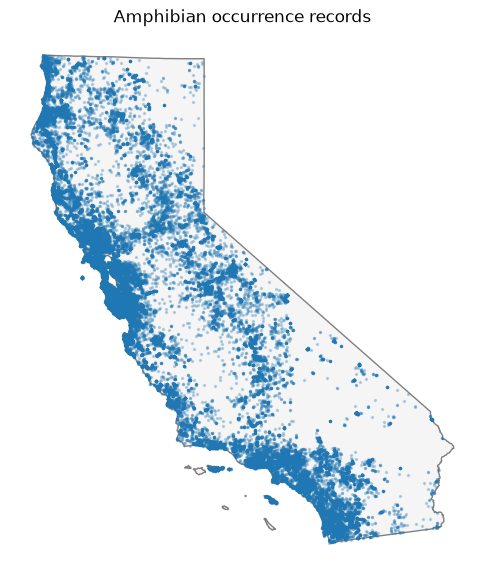

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.mask import mask
from shapely.geometry import box
from scipy.spatial.distance import pdist, squareform
from gdmbayes import GDM

CRS = "EPSG:3310"
GRAINS = [20, 40, 80]
MIN_RECORDS = 1
CLIMATE_DIR = Path("../data/bioclim_CA")
OUTPUT = Path("outputs/Assignment11")
OUTPUT.mkdir(parents=True, exist_ok=True)

california = gpd.read_file("../data/CA_ShapeFiles/California_State_Boundary.shp")
california = california.to_crs(CRS).dissolve()
records = gpd.read_file("../data/CA_amphibians.geojson").to_crs(CRS)
print("Input records:", len(records))
records = records.dropna(subset=["species"])
records = records[records.species != ""]
records = gpd.clip(records, california)
print("Sampled records with species names:", len(records))
print("Species labels:", records.species.nunique())

ax = california.plot(color="whitesmoke", edgecolor="gray", figsize=(6, 7))
records.plot(ax=ax, markersize=2, alpha=0.25)
ax.set_title("Amphibian occurrence records")
ax.set_axis_off()
plt.show()

**Interpretation:** Where are observations concentrated or sparse? Which parts of California might be especially difficult to characterize from these data? Explain why repeated records, uncertain coordinates, and unresolved species names matter for a site-by-species matrix.

*Your answer:* The majority of the observations are concentrated along the coast line. There is also a band of observations running North-South in the interior of the state, presumably along a geographic feature or following human population density. The areas that are most likely to be missing and would be hard to characterize include mountanous regions and the southern interior regions that may include deserts and/or areas of low human population. Repeated records can skew site-by-species matrixes and cause inaccurate abundance calculations. Uncertain coordinate entries could lead to clustering of observations if a local default (e.g., nearby town, county center, etc) is used, which can lead to clustering of observations. Unresolved species names could lead to misidentification and misassignment of species to areas outside of its native range.

## 2. Aggregate records to sites

The helper follows Lab11 but uses the California boundary and a new shared grid
origin. Finer cells nest within coarser cells. Only cells meeting `MIN_RECORDS`
become sites; missing cells are not treated as zero-richness communities.

Map outlines are clipped to the state, but geographic distances use the full
square centers. Coastal and island cells can contain less land than interior
cells of the same nominal grain.

In [2]:
origin_width = max(GRAINS) * 1000
x0 = np.floor(california.total_bounds[0] / origin_width) * origin_width
y0 = np.floor(california.total_bounds[1] / origin_width) * origin_width

def grid_communities(grain_km):
    width = grain_km * 1000
    points = records.copy()
    points["col"] = ((points.geometry.x - x0) // width).astype(int)
    points["row"] = ((points.geometry.y - y0) // width).astype(int)
    points["site_id"] = points.col.astype(str) + "_" + points.row.astype(str)
    community = pd.crosstab(points.site_id, points.species)
    cell_locations = points[["site_id", "col", "row"]].drop_duplicates()
    cells = []
    for cell in cell_locations.itertuples():
        x = x0 + cell.col * width
        y = y0 + cell.row * width
        cells.append({"site_id": cell.site_id, "xc": x + width / 2,
                      "yc": y + width / 2, "geometry": box(x, y, x + width, y + width)})
    sites = gpd.GeoDataFrame(cells, crs=CRS).set_index("site_id")
    sites = gpd.clip(sites, california).sort_index()
    community = community.reindex(sites.index)
    sites["n_records"] = community.sum(axis=1)
    sites["richness"] = (community > 0).sum(axis=1)
    sites = sites[sites.n_records >= MIN_RECORDS].copy()
    return sites, community.loc[sites.index]

In [3]:
sites_by_grain = {}
communities = {}
grain_summary = pd.DataFrame()

# Loop over GRAINS and call grid_communities(grain).
# Store sites_by_grain[grain] and communities[grain], as in Lab11.
# Summarize n_sites, n_records, mean_richness, and median_records_per_site.
# Display grain_summary and the first rows of communities[40].

for grain in GRAINS:                 ## Applying the grid_communities function at each grain size
    sites, community = grid_communities(grain)
    sites_by_grain[grain] = sites    ## Keeping track of the grids and site-by-species matrix at each grain size
    communities[grain] = community
    grain_summary.loc[grain, "n_sites"] = len(sites)
    grain_summary.loc[grain, "n_records"] = sites.n_records.sum()
    grain_summary.loc[grain, "mean_richness"] = sites.richness.mean()
    grain_summary.loc[grain, "median_records_per_site"] = sites.n_records.median()

grain_summary.index.name = "grain_km"
display(grain_summary)
display(communities[40].head())

,n_sites,n_records,mean_richness,median_records_per_site
grain_km,,,,
20,893.0,62829.0,5.456887,19.0
40,278.0,62829.0,8.017986,66.5
80,88.0,62829.0,11.681818,292.0


species,Ambystoma californiense,Ambystoma gracile,Ambystoma macrodactylum,Ambystoma mavortium,Ambystoma texanum,Ambystoma tigrinum,Amerana aurora,Amerana boylii,Amerana cascadae,Amerana draytonii,...,Rhyacotriton variegatus,Scaphiopus couchii,Scaphiopus hurterii,Spea hammondii,Spea intermontana,Taricha granulosa,Taricha rivularis,Taricha sierrae,Taricha torosa,Xenopus laevis
site_id,,,,,,,,,,,,,,,,,,,,,
0_22,0,0,0,0,0,0,0,5,0,0,...,0,0,0,0,0,1,0,0,0,0
0_23,0,0,0,0,0,0,3,3,0,0,...,0,0,0,0,0,1,0,0,0,0
10_10,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10_11,0,0,0,0,0,0,0,0,0,0,...,0,0,0,3,0,0,0,0,0,0
10_12,1,0,0,0,0,0,0,0,0,0,...,0,0,0,4,0,0,0,9,0,0


## 3. Richness and sampling maps

Plot richness for all three grains using one shared color scale. Make a second
comparison of record counts and richness at 20 km. Use `california` as the
background layer when adapting the lab's mapping cells.

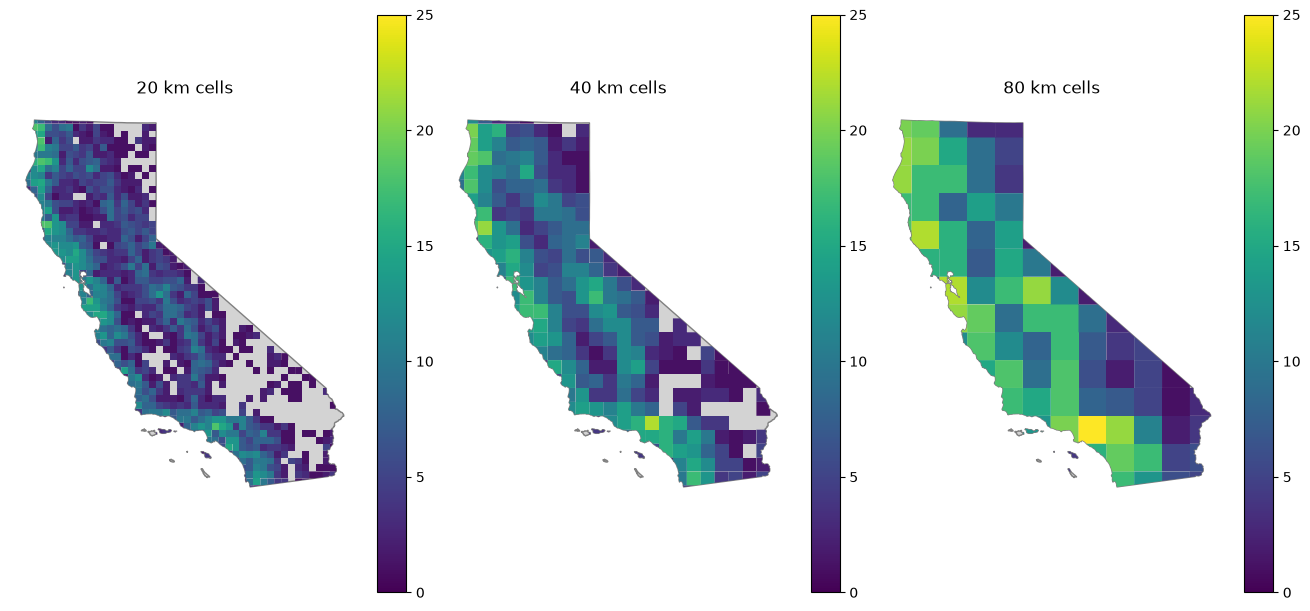

In [4]:
# Create and save the three richness maps with a common color scale.
max_richness = max(sites.richness.max() for sites in sites_by_grain.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="richness", cmap="viridis",
                              vmin=0, vmax=max_richness, legend=True)
    ax.set_title(f"{grain} km cells")
    ax.set_axis_off()
fig.savefig(OUTPUT / "richness_by_grain.png", dpi=150)
plt.show()

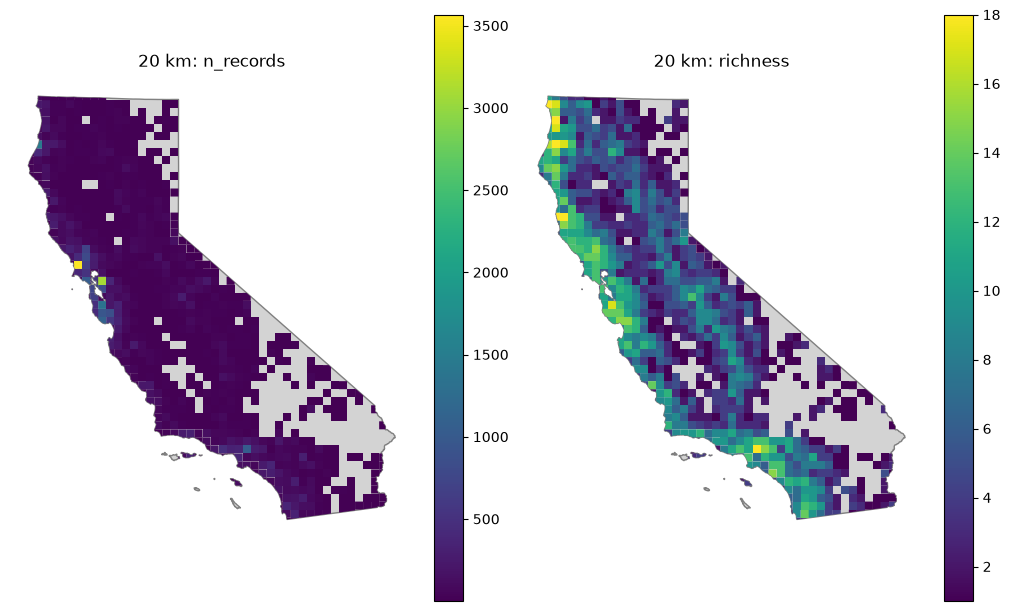

In [5]:
# Compare n_records and richness at 20 km.
fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, column in zip(axes, ["n_records", "richness"]):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[20].plot(ax=ax, column=column, legend=True)
    ax.set_title(f"20 km: {column}")
    ax.set_axis_off()
plt.show()

**Interpretation:** Which richness patterns persist across grains? Which become
more or less apparent? How much might the patterns reflect aggregation,
reporting effort, or differences in the amount of land within a cell?

*Your answer:*
All three richness maps show increased richness along the coast and a band running N-S in the center of the state (presumably along a geographic feature). The 80km grain map starts to lose the pattern compared to the 40km and 20km grain maps. It is notable that the increase in grain size from 20km to either 40km or 80km causes the map to appear as if there are observation records in areas where there are no records available. This could lead to erroneously assigning certain areas as being habitat for these species, when that conclusion may not be supported by data. Border cells may have artificially low richness because of smaller sampling area. A larger cell pools more species so increasing grain size may (but not guaranteed to) increase species richness. 

## 4. Distance decay of similarity

Use presence/absence and **Jaccard dissimilarity**. Similarity is `1 - Jaccard`.
The helpers below retain matching site order and summarize similarity in
100 km distance bands, allowing for California's larger extent.

Plot all pairs and their distance-band means for each grain. Keep similarity
axes fixed at 0–1. Report the descriptive Spearman distance–similarity
correlation, without treating pairs that share sites as independent replicates.

In [6]:
def community_pairs(sites, community):
    presence = community.loc[sites.index] > 0
    dissimilarity = pdist(presence, metric="jaccard")
    distance_km = pdist(sites[["xc", "yc"]]) / 1000
    return pd.DataFrame({"distance_km": distance_km,
                         "jaccard": dissimilarity,
                         "similarity": 1 - dissimilarity})

def distance_bands(pairs):
    rows = []
    for lower in range(0, 1600, 100):
        in_band = pairs[(pairs.distance_km >= lower) & (pairs.distance_km < lower + 100)]
        if len(in_band) == 0:
            continue
        rows.append({"distance_km": in_band.distance_km.mean(),
                     "mean_similarity": in_band.similarity.mean(),
                     "n_pairs": len(in_band)})
    return pd.DataFrame(rows)

,distance_km,jaccard,similarity
0,20.0,0.142857,0.857143
1,40.0,0.294118,0.705882
2,60.0,0.461538,0.538462
3,80.0,0.250000,0.750000
4,100.0,0.437500,0.562500
5,120.0,0.333333,0.666667
6,140.0,0.307692,0.692308
7,160.0,0.384615,0.615385
8,180.0,0.461538,0.538462
9,200.0,0.615385,0.384615


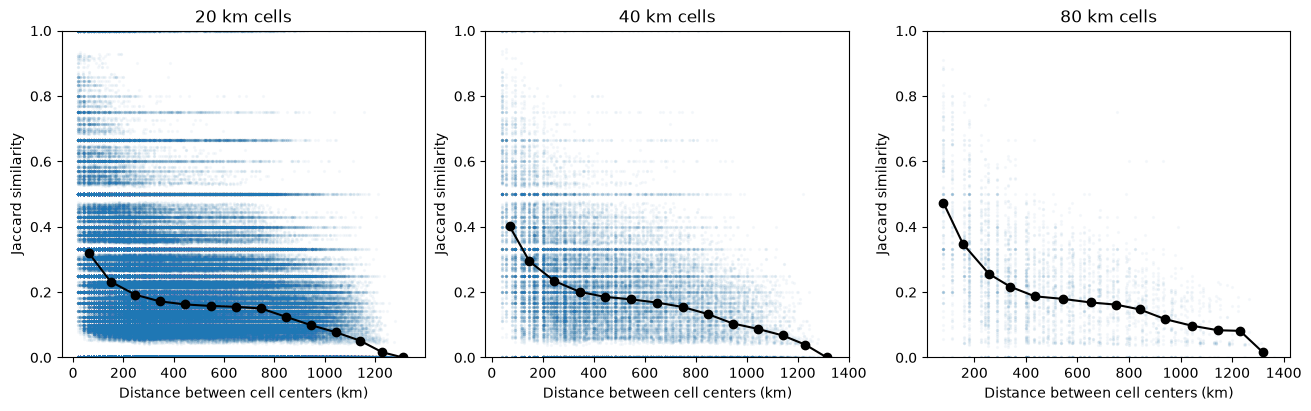

,n_sites,n_records,mean_richness,median_records_per_site,distance_similarity_rho
grain_km,,,,,
20,893.0,62829.0,5.456887,19.0,-0.265722
40,278.0,62829.0,8.017986,66.5,-0.385445
80,88.0,62829.0,11.681818,292.0,-0.456623


In [7]:
pairs_by_grain = {}
binned_decay = {}

# For each grain, calculate community_pairs and distance_bands.
# Make distance-decay plots and calculate the descriptive correlation.
# Inspect n_pairs in the most distant bands before interpreting their means.

for grain in GRAINS:
    pairs_by_grain[grain] = community_pairs(sites_by_grain[grain], communities[grain])

display(pairs_by_grain[20].head(20))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    pairs = pairs_by_grain[grain]
    bands = distance_bands(pairs)
    binned_decay[grain] = bands
    ax.scatter(pairs.distance_km, pairs.similarity, s=2, alpha=0.03)
    ax.plot(bands.distance_km, bands.mean_similarity, color="black", marker="o")
    ax.set(title=f"{grain} km cells", xlabel="Distance between cell centers (km)",
           ylabel="Jaccard similarity", ylim=(0, 1))
    grain_summary.loc[grain, "distance_similarity_rho"] = pairs.distance_km.corr(
        pairs.similarity, method="spearman")
fig.savefig(OUTPUT / "distance_decay_by_grain.png", dpi=150)
plt.show()

display(grain_summary)

**Interpretation:** Does similarity decline steadily, level off, or show another pattern? How does the relationship change with grain? Explain at least two
biological or sampling explanations. Could nested species lists contribute to Jaccard dissimilarity without species replacement?

*Your answer:* The trend of Jaccard similarity decline is similar among the 20km cells, the 40km cells, and the 80km cells. There is a rapid decline up to ~250-300km and then the trend becomes more shallow until there is another decline (less steep) between ~1000km and 1300km. There are slight differences between the grain sizes, but the overall pattern is the same. This pattern could be a result of strong geographic pattern across the state where, regardless of grain size, we see a similar pattern in species richness and abundance distributions. This could also be a result of increased sampling efforts in specific parts of the state (possibly correlated with population centers) that result in similar patterns across grain sizes because of the size of the state. Nested species lists can cause the same Jaccard value as communities of different community composition due to species replacement. 

## 5. Local differences among communities

Reuse the lab's neighbor comparison: mean Jaccard dissimilarity to sampled
cells within **1.5 cell widths**, excluding the focal cell. Map the results for
all three grains with one 0–1 color scale. Leave cells with no sampled neighbors
as missing.

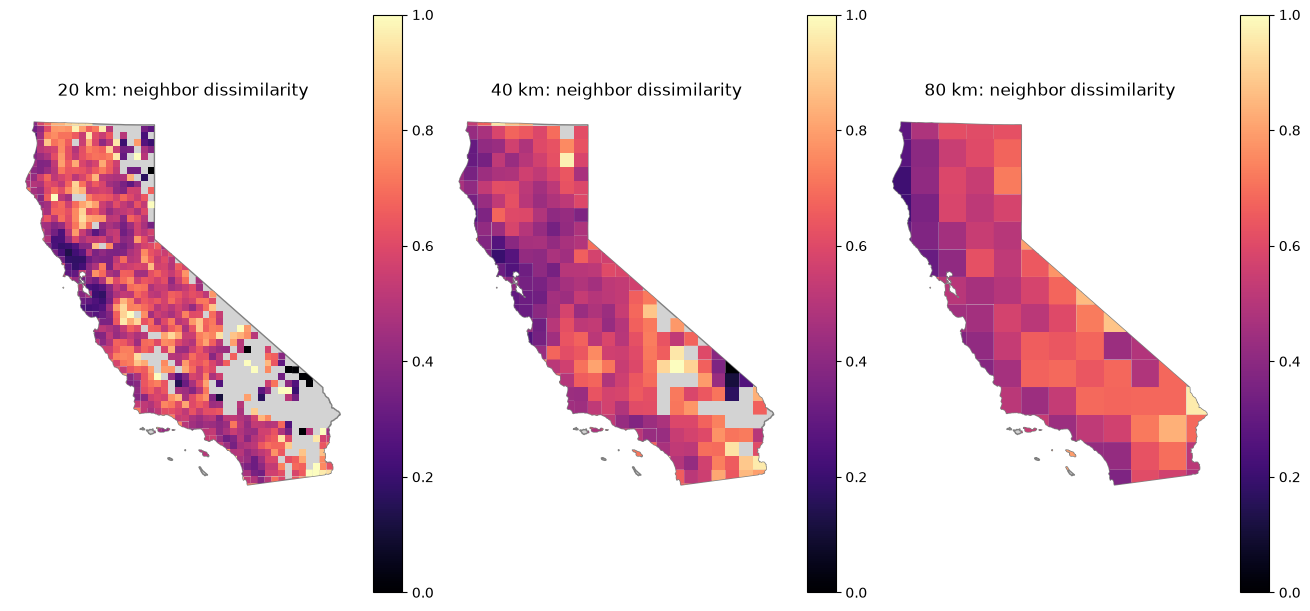

In [8]:
# Use squareform on each grain's distance and dissimilarity vectors.
# Calculate neighbor_dissimilarity for each sampled cell.
# Map and save the three results.

for grain in GRAINS:
    sites = sites_by_grain[grain]
    pairs = pairs_by_grain[grain]
    distances = squareform(pairs.distance_km.to_numpy())   ## Looking at a given site and finding the sites that are geographically proximal to the selected site
    dissimilarities = squareform(pairs.jaccard.to_numpy())
    local_difference = []
    for i in range(len(sites)):
        neighbors = (distances[i] > 0) & (distances[i] <= 1.5 * grain)
        if neighbors.any():
            local_difference.append(dissimilarities[i, neighbors].mean())
        else:
            local_difference.append(np.nan)
    sites["neighbor_dissimilarity"] = local_difference

fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="neighbor_dissimilarity", cmap="magma",
                              vmin=0, vmax=1, legend=True)
    ax.set_title(f"{grain} km: neighbor dissimilarity")
    ax.set_axis_off()
    
fig.savefig(OUTPUT / "neighbor_dissimilarity_by_grain.png", dpi=150)
plt.show()

In [9]:
## Compare two contrasting sites and inspect their species list and record totals
sites = sites_by_grain[40]

# Drop cells with no sampled neighbors, and require a minimum record count
valid = sites.dropna(subset=["neighbor_dissimilarity"])

ranked = valid.sort_values("neighbor_dissimilarity")
display(ranked[["neighbor_dissimilarity", "n_records", "richness"]].head(5))   # lowest
display(ranked[["neighbor_dissimilarity", "n_records", "richness"]].tail(5))   # highest

low_site = ranked.index[0]
high_site = ranked.index[-1]

for site in [low_site, high_site]:
    counts = communities[40].loc[site]
    print(site, "| neighbor dissimilarity:", round(sites.loc[site, "neighbor_dissimilarity"], 3),
          "| total records:", int(counts.sum()))
    display(counts[counts > 0].sort_values(ascending=False))

,neighbor_dissimilarity,n_records,richness
site_id,,,
20_9,0.000000,1,1
20_8,0.111111,3,1
20_7,0.166667,11,1
3_17,0.197874,1146,14
21_8,0.250000,3,1


,neighbor_dissimilarity,n_records,richness
site_id,,,
16_10,0.952381,33,1
15_2,0.955032,2,1
22_2,0.958333,4,2
8_24,0.968750,1,1
16_9,1.000000,1,1


20_9 | neighbor dissimilarity: 0.0 | total records: 1


species
Anaxyrus punctatus    1
Name: 20_9, dtype: int64

16_9 | neighbor dissimilarity: 1.0 | total records: 1


species
Aquarana catesbeiana    1
Name: 16_9, dtype: int64

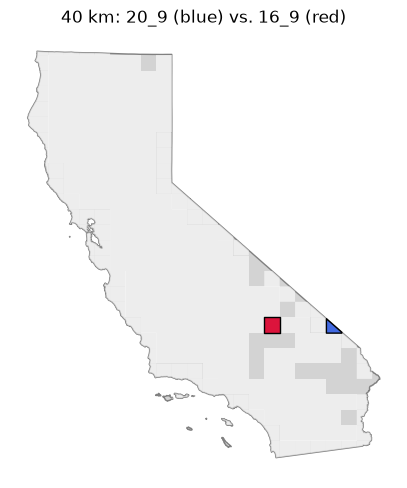

In [10]:
## Select the two sites for comparison and then map to see where they are
grain = 40
site_a = low_site     # or select site_id
site_b = high_site

sites = sites_by_grain[grain]

fig, ax = plt.subplots(figsize=(5, 6))
california.plot(ax=ax, color="lightgray", edgecolor="gray")
sites.plot(ax=ax, color="white", edgecolor="none", alpha=0.6)            # all sampled cells
sites.loc[[site_a]].plot(ax=ax, color="royalblue", edgecolor="black")    # site A. using double brackets so it stays a GeoDataFrame (needed for .plot())
sites.loc[[site_b]].plot(ax=ax, color="crimson", edgecolor="black")      # site B
ax.set_title(f"{grain} km: {site_a} (blue) vs. {site_b} (red)")
ax.set_axis_off()
plt.show()

**Interpretation:** Where are neighboring recorded communities most different?
Choose two contrasting sites and inspect their species lists and record totals.
Why is this not a map of pure species replacement or turnover per kilometer?

*Your answer:* I'm not sure that I built the code for contrasting two sites correctly, but if this is correct we are seeing perfectly opposite similarity for these sites becaue they each have exactly one record and it is a different species. This would provide the perfect 0 and 1 values from the table. We could apply a filter to number of records per cell in order to filter out the cells with only one (or a few) observations in order to avoid this situation. Based on the earlier maps, the neighboring recorded communities are most different in the interior and southeastern regions of the state (most easily visualized with the 20km grain size). These are also the regions with the fewest number of observations and most areas of missing values. This is not pure species replacement because it isn't corrected for sampling effort, there could be nested species within these cells, and the areas near borders are not corrected for having fewer cells for comparison (is this considered an "edge effect"?). 

## 6. Summarize site climate

Use **all 19 bioclimatic variables**, matching the revised Lab11 and its
predictor names. Each site's climate is the mean of valid raster pixels
intersecting its land area. Edge pixels are included equally; this is an
approximate zonal mean, not an exact area-weighted average.

Inspect the ranges and correlations of all predictors. For orientation, map
`temperature_c` (BIO1) and `precip` (BIO12) at 40 km. These are example maps;
**all 19 variables enter every full GDM and the PCA**. Several predictors describe
related aspects of climate, so their fitted contributions can overlap.

In [11]:
CLIMATE_LAYERS = {
    'wc2.1_2.5m_bio_1.tif': 'temperature_c',
    'wc2.1_2.5m_bio_2.tif': 'diurnal_range_c',
    'wc2.1_2.5m_bio_3.tif': 'isothermality',
    'wc2.1_2.5m_bio_4.tif': 'temp_seasonality',
    'wc2.1_2.5m_bio_5.tif': 'max_temp_warmest',
    'wc2.1_2.5m_bio_6.tif': 'min_temperature_coldest',
    'wc2.1_2.5m_bio_7.tif': 'temp_range',
    'wc2.1_2.5m_bio_8.tif': 'temp_wettest_q',
    'wc2.1_2.5m_bio_9.tif': 'temp_driest_q',
    'wc2.1_2.5m_bio_10.tif': 'temp_warmest_q',
    'wc2.1_2.5m_bio_11.tif': 'temp_coldest_q',
    'wc2.1_2.5m_bio_12.tif': 'precip',
    'wc2.1_2.5m_bio_13.tif': 'precip_wettest_m',
    'wc2.1_2.5m_bio_14.tif': 'precip_driest_m',
    'wc2.1_2.5m_bio_15.tif': 'precip_seasonality',
    'wc2.1_2.5m_bio_16.tif': 'precip_wettest_q',
    'wc2.1_2.5m_bio_17.tif': 'precip_driest_q',
    'wc2.1_2.5m_bio_18.tif': 'precip_warmest_q',
    'wc2.1_2.5m_bio_19.tif': 'precip_coldest_q',
}

predictors = list(CLIMATE_LAYERS.values())

def add_climate(sites, climate_dir=CLIMATE_DIR):
    sites = sites.copy()
    for filename, name in CLIMATE_LAYERS.items():
        means = []
        with rasterio.open(climate_dir / filename) as raster:
            raster_sites = sites.to_crs(raster.crs)
            for geometry in raster_sites.geometry:
                pixels, transform = mask(raster, [geometry], crop=True,
                                         filled=False, all_touched=True)
                valid_pixels = pixels[0].compressed()
                if len(valid_pixels) == 0:
                    means.append(np.nan)
                else:
                    means.append(valid_pixels.mean())
        sites[name] = means
    return sites

In [12]:
climate_sites = {}

# Call add_climate for each grain using all 19 layers.
# Report missing climate values and inspect all predictor ranges and correlations.

for grain in GRAINS:
    sites = add_climate(sites_by_grain[grain])
    climate_sites[grain] = sites
    print(grain, "km: sites missing climate =", sites[predictors].isna().any(axis=1).sum())

display(climate_sites[20][predictors].describe())
display(climate_sites[20][predictors].corr())

20 km: sites missing climate = 4
40 km: sites missing climate = 0
80 km: sites missing climate = 0


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
count,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000
mean,13.475358,14.790231,48.567244,602.000201,31.042590,0.093453,30.949137,7.586922,19.953004,21.152805,6.606853,642.986673,118.140172,3.920115,78.010818,325.715776,21.394728,29.341772,315.940638
std,4.425070,1.839180,5.352188,149.747160,5.170913,4.432333,5.486666,5.457071,3.981870,4.782529,4.481932,422.845817,77.013003,3.863695,14.990538,214.693665,17.681632,19.154836,208.732184
min,0.162917,6.977362,38.331367,208.296799,17.939335,-12.948133,14.631445,-6.383956,7.028044,9.153378,-6.501844,65.444443,11.000000,0.000000,34.753639,27.166666,2.000000,2.000000,26.500000
25%,10.519701,14.006972,44.870064,524.416138,27.368687,-1.950971,28.928572,4.455692,16.780901,17.306116,3.922982,340.966675,60.066666,1.000000,69.251411,167.634140,6.466667,12.694445,160.199997
50%,14.282757,14.944526,46.912304,642.613098,30.812098,1.369889,32.020569,8.568976,20.028067,20.939676,8.067652,510.516144,98.300003,2.171429,82.460823,269.566681,13.714286,24.161291,260.566681
75%,16.458937,15.917021,52.038784,701.079285,34.842934,2.909300,34.723671,10.262364,23.259218,24.149723,9.154537,895.806458,167.800003,6.150000,88.783730,453.914276,36.529411,45.076923,447.214294
max,23.964811,19.658438,67.010284,920.603943,43.082802,9.190751,41.423744,32.447491,28.552822,33.829708,14.684394,2052.777832,353.578949,18.714285,106.641960,1024.125000,76.333336,90.777779,979.375000


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
temperature_c,1.000000,0.104647,0.047805,0.071529,0.783617,0.839856,0.060054,0.911456,0.883876,0.920367,0.918208,-0.508560,-0.447219,-0.866303,0.163608,-0.453070,-0.811908,-0.685737,-0.455560
diurnal_range_c,0.104647,1.000000,-0.413366,0.698882,0.612299,-0.348488,0.858583,-0.081493,0.333392,0.366919,-0.174847,-0.381350,-0.418778,0.022036,-0.412554,-0.411820,-0.024686,-0.055878,-0.410445
isothermality,0.047805,-0.413366,1.000000,-0.921567,-0.460128,0.467570,-0.811368,0.237596,-0.217913,-0.316450,0.406892,0.280316,0.347135,-0.260644,0.628655,0.350601,-0.200969,-0.176025,0.345667
temp_seasonality,0.071529,0.698882,-0.921567,1.000000,0.639754,-0.446898,0.963958,-0.144380,0.327156,0.453174,-0.325367,-0.401792,-0.466324,0.168664,-0.695932,-0.467800,0.107504,0.101326,-0.462505
max_temp_warmest,0.783617,0.612299,-0.460128,0.639754,1.000000,0.355170,0.655532,0.577744,0.885600,0.949246,0.491714,-0.579246,-0.570858,-0.565745,-0.240452,-0.573305,-0.538057,-0.463984,-0.573183
min_temperature_coldest,0.839856,-0.348488,0.467570,-0.446898,0.355170,1.000000,-0.473107,0.876051,0.621741,0.576156,0.973028,-0.143191,-0.056826,-0.849087,0.526319,-0.062262,-0.729292,-0.608459,-0.067076
temp_range,0.060054,0.858583,-0.811368,0.963958,0.655532,-0.473107,1.000000,-0.163212,0.332368,0.429177,-0.322632,-0.430236,-0.492100,0.152738,-0.651794,-0.490014,0.082057,0.054253,-0.486010
temp_wettest_q,0.911456,-0.081493,0.237596,-0.144380,0.577744,0.876051,-0.163212,1.000000,0.709114,0.759139,0.921898,-0.371261,-0.307083,-0.802443,0.232647,-0.311310,-0.739763,-0.581581,-0.316694
temp_driest_q,0.883876,0.333392,-0.217913,0.327156,0.885600,0.621741,0.332368,0.709114,1.000000,0.912363,0.705242,-0.510965,-0.467663,-0.770921,0.145334,-0.472633,-0.727706,-0.708030,-0.473550
temp_warmest_q,0.920367,0.366919,-0.316450,0.453174,0.949246,0.576156,0.429177,0.759139,0.912363,1.000000,0.695238,-0.606594,-0.577353,-0.704550,-0.125728,-0.582392,-0.678684,-0.561071,-0.582916


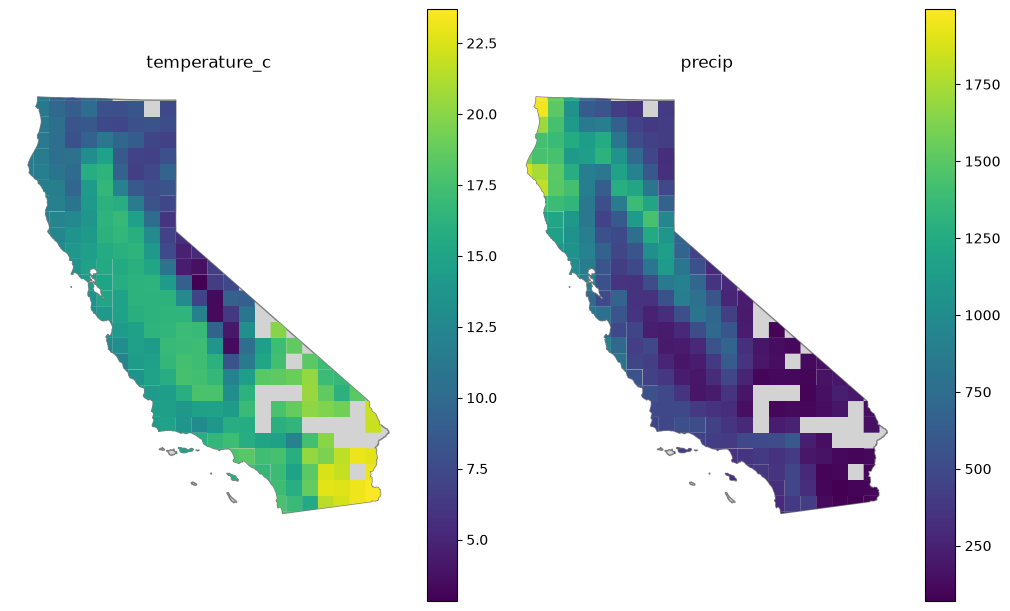

In [13]:
# Map temperature_c and precip at 40 km as examples of the gradients.
clim_var = ["temperature_c", "precip"]

fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, name in zip(axes.flat, clim_var):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    climate_sites[40].plot(ax=ax, column=name, legend=True)
    ax.set_title(name)
    ax.set_axis_off()
plt.show()

**Interpretation:** How do the environmental gradients differ from Maine's? Why might averaging climate over larger cells conceal meaningful habitat
variation? What does a 1970–2000 climate average leave out when explaining occurrences collected across different years?

*Your answer:* The climate patterns in Maine were mostly a consistent gradient from the coast to the interior, showing relatively smooth changes over geographical space. The climate patterns in California show a more distinct pattern with a unique feature in the center of the state and pockets on the coast similar to the interior (eastern state border). As we increase cell size, we start to loose the localized climate patterns that can drive variations in habitat use by species of interest. Additionally, we know that the climate patterns are changing at a rapid rate, particularly in the most recent few years, which could lead to errors when comparing climatology from 1970-2000 with occurrence records that have been recorded more recently. Ideally, the climate timeframe would match with the occurence records. 

## 7. Fit GDM at each grain

Reuse the lab's standard `GDM(geo=True, knots=0)` setup. Drop sites missing
climate, align their community rows, and **recompute** Jaccard pairs. `X` must
start with `xc`, `yc`, and `time_idx`, followed by all 19 climate variables, in the order in predictors.
Use zero for `time_idx` because years are pooled; it is a required placeholder.

Fit a geography-only baseline and then geography plus climate at each grain.
Report site counts, pair counts, training deviance explained, and predictor
transformation heights. Check `n_sites * (n_sites - 1) / 2` before fitting;
20/40/80 km grids keep this larger-state exercise manageable. Use all retained
sites from the supplied occurrence sample for the main comparison; do not
downsample it again.

In [14]:
model_sites = {}
model_X = {}
model_y = {}

for grain in GRAINS:
    sites = climate_sites[grain].dropna(subset=predictors).copy()
    community = communities[grain].loc[sites.index]
    X = sites[["xc", "yc"]].copy()
    X["time_idx"] = 0
    X[predictors] = sites[predictors]
    y = pdist(community > 0, metric="jaccard")
    model_sites[grain] = sites
    model_X[grain] = X
    model_y[grain] = y
    n = len(X)
    print(grain, "km:", n, "sites and", len(y), "pairs | check n*(n-1)/2 =", n * (n - 1) // 2)

display(model_X[20].head())

20 km: 889 sites and 394716 pairs | check n*(n-1)/2 = 394716
40 km: 278 sites and 38503 pairs | check n*(n-1)/2 = 38503
80 km: 88 sites and 3828 pairs | check n*(n-1)/2 = 3828


,xc,yc,time_idx,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,...,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
site_id,,,,,,,,,,,,,,,,,,,,,
10_26,-190000.0,-110000.0,0,13.781463,12.696052,60.599255,319.376038,24.826563,3.832474,20.994087,...,17.780729,10.027334,836.409119,175.409088,3.000000,93.258057,454.318176,11.045455,16.590910,450.863647
10_27,-190000.0,-90000.0,0,13.741483,12.179098,56.419796,366.827057,25.508621,3.869755,21.638866,...,18.445585,9.538509,851.514282,175.685715,2.771429,92.305855,454.285706,11.257143,17.142857,453.685699
10_28,-190000.0,-70000.0,0,14.440726,12.002498,55.116814,380.460205,26.009619,4.223004,21.786612,...,19.140898,9.885418,624.583313,126.750000,2.000000,90.400826,330.388885,8.416667,12.888889,327.166656
10_29,-190000.0,-50000.0,0,14.844004,11.200382,54.022446,367.577087,25.456203,4.725770,20.730434,...,19.142586,10.179401,434.115387,87.346153,1.115385,88.832817,230.192307,5.923077,9.038462,224.923080
10_30,-190000.0,-30000.0,0,14.864372,11.091510,53.493465,374.604401,25.909904,5.152510,20.757395,...,19.277126,10.141910,540.782593,112.086960,1.217391,90.384880,291.695648,7.086957,10.695652,287.260864


In [15]:
models = {}
predictions = {}
gdm_summary = pd.DataFrame()
importance = pd.DataFrame()

for grain in GRAINS:
    X = model_X[grain]
    y = model_y[grain]
    geography_only = GDM(geo=True, knots=0).fit(X[["xc", "yc", "time_idx"]], y)
    model = GDM(geo=True, knots=0).fit(X, y)
    models[grain] = model
    predictions[grain] = model.predict(X)
    gdm_summary.loc[grain, "n_sites"] = len(X)
    gdm_summary.loc[grain, "n_pairs"] = len(y)
    gdm_summary.loc[grain, "geography_only_deviance_pct"] = 100 * geography_only.explained_
    gdm_summary.loc[grain, "training_deviance_explained_pct"] = 100 * model.explained_
    for name, value in model.predictor_importance_.items():
        importance.loc[grain, name] = value

gdm_summary.index.name = "grain_km"
importance.index.name = "grain_km"
display(gdm_summary)
display(importance)

,n_sites,n_pairs,geography_only_deviance_pct,training_deviance_explained_pct
grain_km,,,,
20,889.0,394716.0,7.531537,21.102688
40,278.0,38503.0,15.692865,41.373078
80,88.0,3828.0,23.856701,60.836791


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q,geo
grain_km,,,,,,,,,,,,,,,,,,,,
20,0.0,0.473103,0.340997,0.335432,0.0,0.147028,0.0,1.305227,0.079940,0.661524,0.0,0.0,0.0,0.000000,0.470264,0.747610,0.0,0.467122,0.0,0.311049
40,0.0,0.352358,0.487095,0.253230,0.0,0.156187,0.0,1.336565,0.000000,0.572586,0.0,0.0,0.0,0.098212,0.950021,0.633492,0.0,0.503948,0.0,0.375995
80,0.0,0.360675,0.841112,0.000000,0.0,0.295647,0.0,1.120253,0.079491,0.408661,0.0,0.0,0.0,0.195887,0.931274,0.565974,0.0,0.154315,0.0,0.439850


## 8. Interpret the fitted models

Plot observed versus predicted Jaccard dissimilarity for each grain. Reuse the
lab's `climate_curve` helper to show the GDM transformations of **all 19
predictors**, comparing grains on each panel. A 5-by-4 panel layout leaves room
for the 19 curves. Label predictors and partial ecological distance; the x axis
uses each variable's original WorldClim scale.

Several variables are correlated. A small transformation height does not show
that a climate process is biologically unimportant; another variable may
represent similar information.

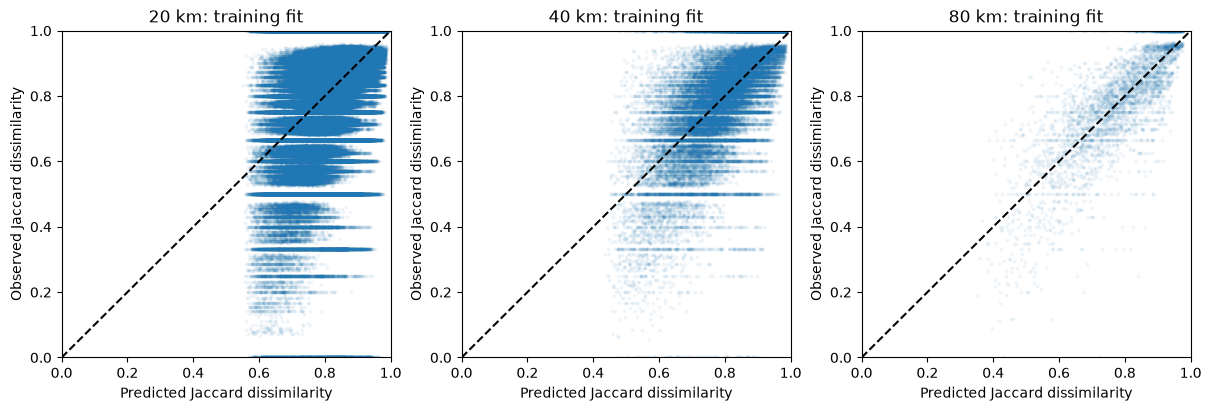

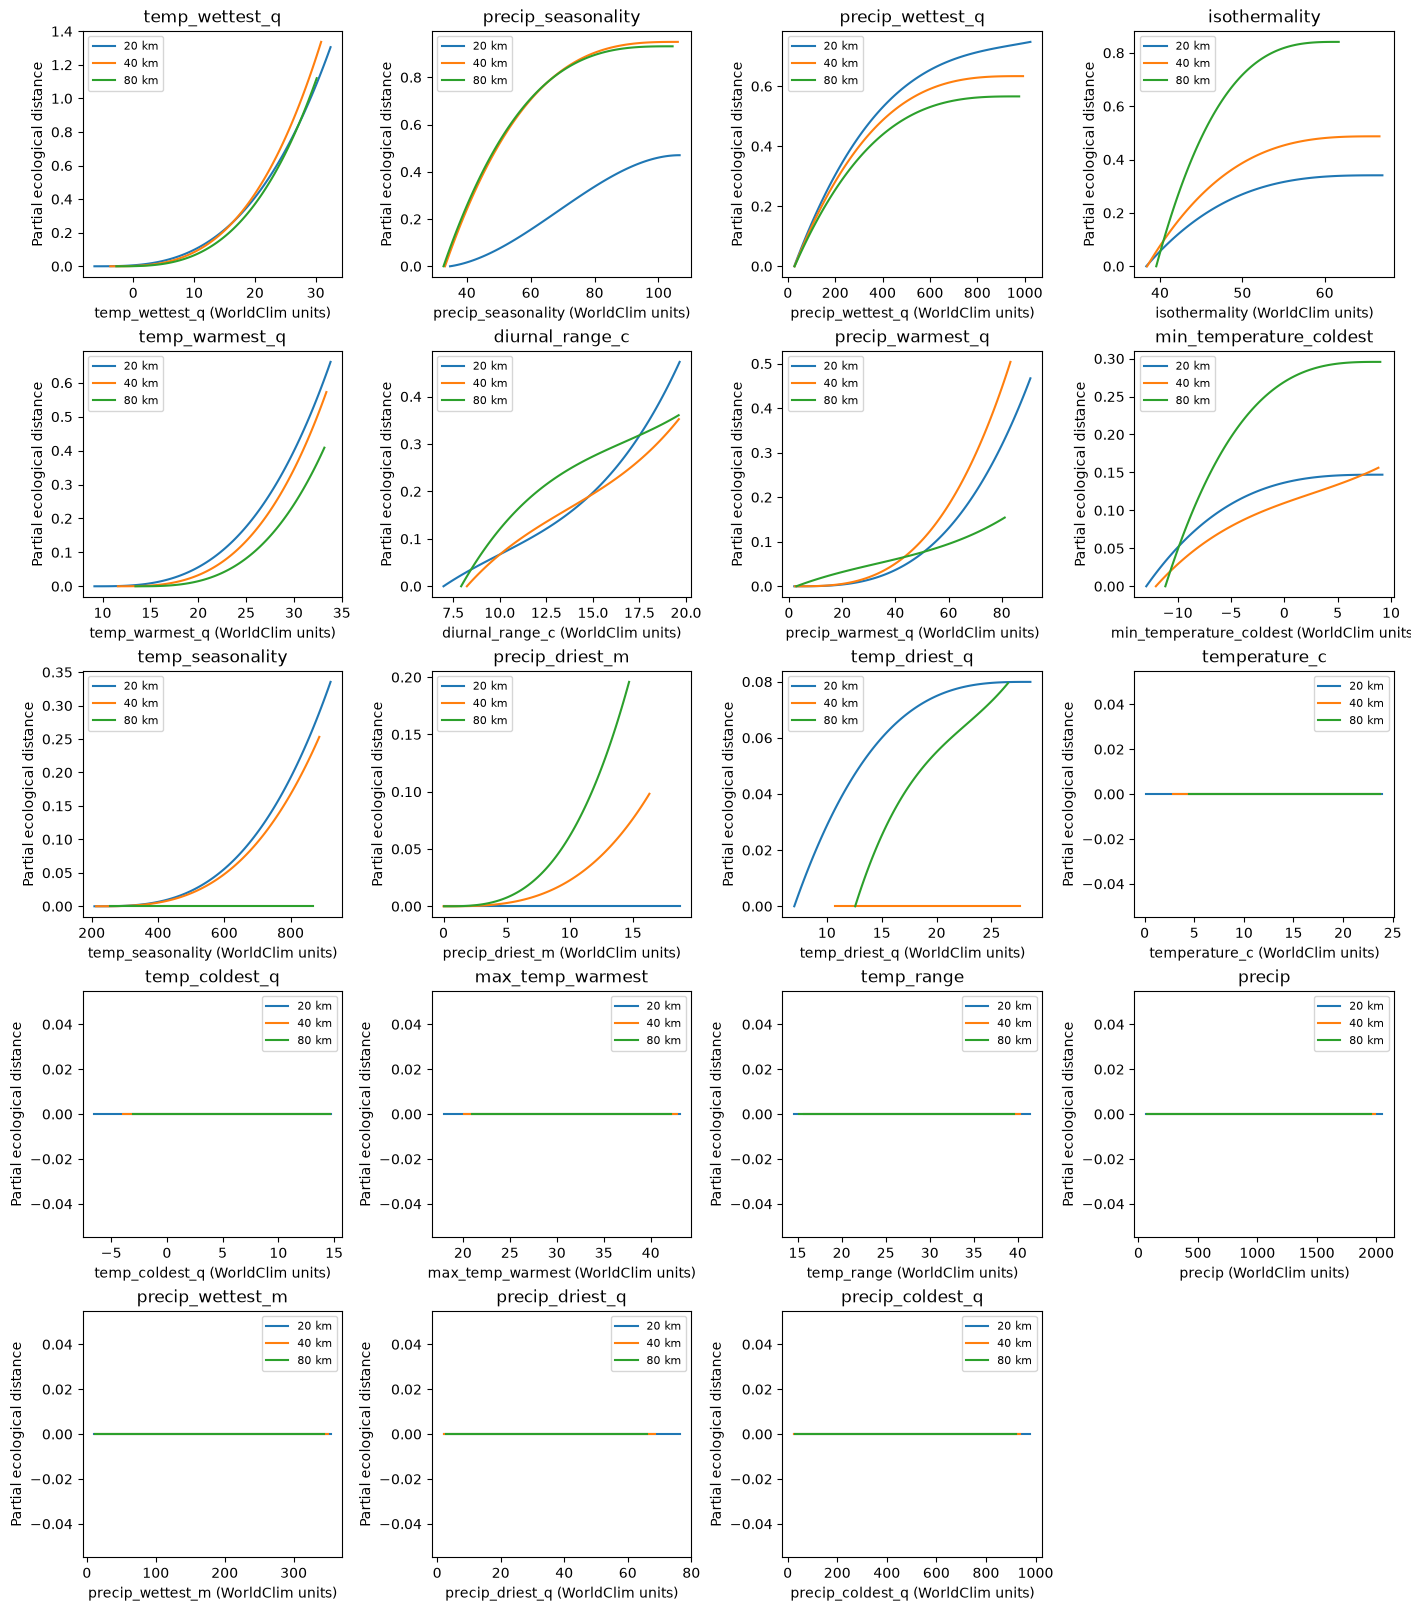

In [16]:
# Make the three observed-versus-predicted plots with 1:1 lines.

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    ax.scatter(predictions[grain], model_y[grain], s=3, alpha=0.05)
    ax.plot([0, 1], [0, 1], color="black", linestyle="--")
    ax.set(title=f"{grain} km: training fit", xlabel="Predicted Jaccard dissimilarity",
           ylabel="Observed Jaccard dissimilarity", xlim=(0, 1), ylim=(0, 1))
fig.savefig(OUTPUT / "gdm_training_fit_by_grain.png", dpi=150)
plt.show()

# Reuse climate_curve from Lab11 and calculate curves for all 19 predictors.
# Plot the three grains together for each predictor in a 5-by-4 panel layout.
# Label predictors and partial ecological distance; hide the unused panel.

sorted_cols = importance.sum().sort_values(ascending=False).index
importance_sorted = importance[sorted_cols].drop(columns=["geo"])

def climate_curve(model, X, predictor):
    curve = pd.DataFrame(index=range(100))
    for column in X.columns:
        curve[column] = X[column].median()
    curve[predictor] = np.linspace(X[predictor].min(), X[predictor].max(), 100)
    effect = model.gdm_transform(curve).sum(axis=1)
    effect = effect - effect[0]
    return pd.DataFrame({"value": curve[predictor], "effect": effect})

curves = {}

fig, axes = plt.subplots(5, 4, figsize=(14, 16), layout="constrained")
for ax, name in zip(axes.flat, importance_sorted.columns):
    for grain in GRAINS:
        curve = climate_curve(models[grain], model_X[grain], name)
        curves[(grain, name)] = curve
        ax.plot(curve.value, curve.effect, label=f"{grain} km")
    ax.set(title=name, xlabel=f"{name} (WorldClim units)",
           ylabel="Partial ecological distance")
    ax.legend(fontsize=8)

# Hide the unused panel
for ax in axes.flat[len(importance_sorted.columns):]:
    ax.set_visible(False)

fig.savefig(OUTPUT / "gdm_climate_curves_by_grain.png", dpi=150)
plt.show()

In [17]:
comparison = grain_summary.join(gdm_summary, rsuffix="_gdm")
display(comparison)

,n_sites,n_records,mean_richness,median_records_per_site,distance_similarity_rho,n_sites_gdm,n_pairs,geography_only_deviance_pct,training_deviance_explained_pct
grain_km,,,,,,,,,
20,893.0,62829.0,5.456887,19.0,-0.265722,889.0,394716.0,7.531537,21.102688
40,278.0,62829.0,8.017986,66.5,-0.385445,278.0,38503.0,15.692865,41.373078
80,88.0,62829.0,11.681818,292.0,-0.456623,88.0,3828.0,23.856701,60.836791


**Interpretation:** How much does adding climate improve training fit over geography alone? Which environmental intervals show the most modeled change?
Which conclusions persist across grains? Explain why transformation heights are not p-values, why a curve is not a habitat optimum, and why training
fit is not evidence of geographic transfer accuracy.

*Your answer:* The steepest and tallest curves are for "temp_wettest_q". "Precip_seasonality" also has a steep and tall curve for the 40km and 80km grain sizes. There is not a consistent pattern of differences between the intervals - for some climate predictors, there is a distinct difference between 20km and 40/80km, but that varies by predictor and some predictors we see no differences at all between the intervals. The height relates to the total dissimilarity not the significance. These variables can be correlated and a flat curve doesn't necessarily mean that it isn't an important parameter. This model is based on site pairs, which has inherent correlation because of shared adjacent sites. For evaluting accuracy, we would need to test on a separate testing dataset and evalute the predictive power. 

## 9. PCA map and biplot of expected composition

Adapt the PCA cell near the end of Lab11. Start with `pca_grain = 40`.
Sum each predictor's weighted spline components to make **19 transformed
columns**, then run PCA **without standardizing them**. This preserves the GDM
weights. Use the first two PC scores to color a California map and a PC1/PC2
scatterplot with the same color key. Report their explained-variance percentages.

Identify and label **only the two variables with the largest loading-vector
lengths across PC1 and PC2**. Calculate loadings as in the lab, then use
`sqrt(PC1_loading**2 + PC2_loading**2)` to measure each arrow's length. A signed
sum can cancel large loadings or change when an axis flips. Display the ranked
loadings table and draw the selected two arrows on the biplot. Also map those
two original climate variables to help interpret their spatial gradients.

Similar colors indicate similar climate-associated expected composition **in
the displayed two-component summary**. They do not encode richness or calibrated
Jaccard distance, and the remaining PCs may contain meaningful variation. GDM's
separate geographic-distance effect is excluded from the site-level
transformation. Each model's PCA and color scale are independent; do not compare
matching colors between states or separately fitted grains as a shared key.

PC1: 57.6%
PC2: 22.5%
PC1 + PC2: 80.0%
Remaining variation in other PCs: 20.0%


,PC1_loading,PC2_loading,vector_length
precip_seasonality,0.148982,9.950645e-02,1.791565e-01
precip_wettest_q,0.170648,-2.655434e-04,1.706477e-01
temp_wettest_q,-0.102291,1.286967e-01,1.643970e-01
temp_warmest_q,-0.108869,5.031477e-02,1.199331e-01
isothermality,0.073887,4.136528e-02,8.467846e-02
temp_seasonality,-0.051173,-1.793387e-02,5.422498e-02
precip_warmest_q,0.014593,-2.381557e-02,2.793094e-02
diurnal_range_c,-0.021692,-1.104286e-02,2.434102e-02
min_temperature_coldest,0.000088,1.995903e-02,1.995922e-02
precip_driest_m,0.000791,-6.218688e-03,6.268848e-03


Two longest loading vectors: ['precip_seasonality', 'precip_wettest_q']


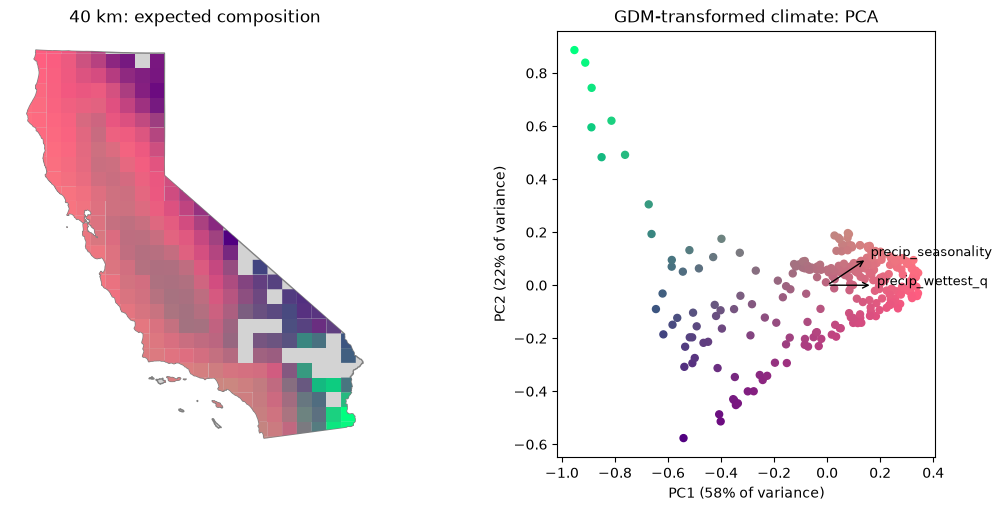

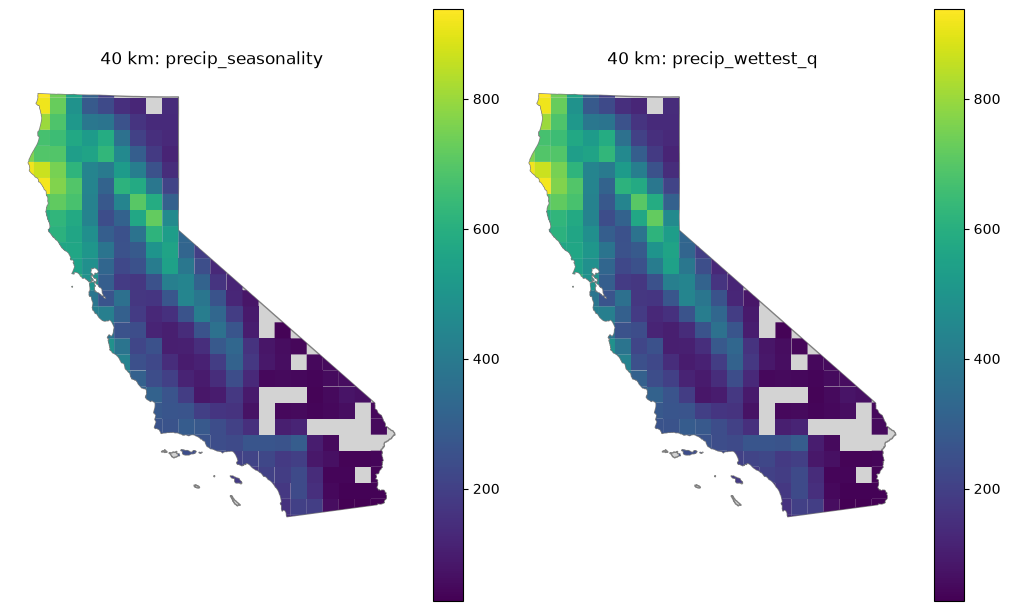

In [18]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

pca_grain = 40
X_biplot = model_X[pca_grain]
model = models[pca_grain]

# Adapt the Lab11 PCA map/biplot cell using all 19 predictors and california.
# Create a loadings table with PC1, PC2, and vector length for every predictor.
# Select the two longest vectors, display their names, and draw only their arrows.
# Save the PCA figure and map the two selected original climate variables.

# Sum each predictor's weighted spline components 
weighted_splines = model.gdm_transform(X_biplot)
n_basis = model.preprocessor_.n_spline_bases_
#print("spline matrix shape:", weighted_splines.shape, "| expected columns:", len(predictors) * n_basis)
transformed = pd.DataFrame(index=X_biplot.index)
for i, name in enumerate(predictors):
    start = i * n_basis
    stop = start + n_basis
    transformed[name] = weighted_splines[:, start:stop].sum(axis=1)

pca = PCA(n_components=2)
scores = pca.fit_transform(transformed)
scaled_scores = MinMaxScaler(clip=True).fit_transform(scores)
colors = np.column_stack([scaled_scores, np.full(len(scores), 0.5)])

print(f"PC1: {pca.explained_variance_ratio_[0]:.1%}")
print(f"PC2: {pca.explained_variance_ratio_[1]:.1%}")
print(f"PC1 + PC2: {pca.explained_variance_ratio_[:2].sum():.1%}")
print(f"Remaining variation in other PCs: {1 - pca.explained_variance_ratio_[:2].sum():.1%}")

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_table = pd.DataFrame(loadings, index=predictors, columns=["PC1_loading", "PC2_loading"])
loadings_table["vector_length"] = np.sqrt(loadings_table.PC1_loading**2 + loadings_table.PC2_loading**2)
loadings_table = loadings_table.sort_values("vector_length", ascending=False)
display(loadings_table)
idx = loadings_table.index[:2].tolist()
print("Two longest loading vectors:", idx)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
california.plot(ax=axes[0], color="lightgray", edgecolor="gray")
model_sites[pca_grain].loc[X_biplot.index].plot(ax=axes[0], color=colors)
axes[0].set_title(f"{pca_grain} km: expected composition")
axes[0].set_axis_off()

axes[1].scatter(scores[:, 0], scores[:, 1], c=colors, s=25)

for i in idx:
    vector = loadings_table.loc[i, ["PC1_loading", "PC2_loading"]].to_numpy(dtype=float)
    axes[1].annotate("", xy=vector, xytext=(0, 0),
                     arrowprops={"arrowstyle": "->", "color": "black"})
    axes[1].text(vector[0] * 1.1, vector[1] * 1.1, i, fontsize=9)
axes[1].set(title="GDM-transformed climate: PCA",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
axes[1].set_aspect("equal")
fig.savefig(OUTPUT / f"gdm_pca_biplot_{pca_grain}_km.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, i in zip(axes, idx):
    california.plot(ax=ax, color="lightgray", edgecolor="gray")
    model_sites[pca_grain].loc[X_biplot.index].plot(ax=ax, column=name, legend=True)
    ax.set_title(f"{pca_grain} km: {i}")
    ax.set_axis_off()
fig.savefig(OUTPUT / f"pca_top_variables_{pca_grain}_km.png", dpi=150)
plt.show()

loadings_table.to_csv(OUTPUT / f"Assignment11_pca_loadings_{pca_grain}_km.csv")

**Interpretation:** Which two variables have the longest loading vectors? What fraction of transformed variation do the first two PCs retain? Where does modeled composition change most strongly, and how do the selected climate gradients relate to that pattern? Why might the longest PCA arrows differ from the predictors with the largest GDM transformation heights? Compare the PCA map with richness and neighbor dissimilarity. Why do these maps answer different
questions?

*Your answer:* "precip_seasonality" and "precip_wettest_q" ahd the longest loading vectors. At 40 km, PC1 explains ~58% and PC2 explains ~22% of the variation in the GDM-transformed climate columns, so together they capture 80% of the variation. This means, similar colors indicate similar climate-associated community composition. Richness asks "how many species were recorded in each grain". It is a count that depends on effort. Neighbor dissimilarity asks "how different is a cell’s species list from the species list of adjacent cells". It depends on sampling, nestedness, and the number of neighbors. The PCA map asks "how are differences in communities expected to be based on climate, using the fitted GDM". It covers every site with climate, treating them the same regardless of how many species records it contains.

## 11. Save results and synthesize

Save the main site layers, community matrices, distance-band summaries, GDM
inputs and predictions, model-comparison tables, all 19 climate curves, the PCA loadings table, and PCA figures
in `OUTPUT`. Save sensitivity results with distinct names.

Write a **400–600 word synthesis** answering the main question: what can these
data tell us about spatial community composition in California, and which
conclusions depend on grain or sampling? Support it with numerical examples and
at least three figures. Identify one concrete additional survey or biological
dataset that would help distinguish competing explanations.

*Your synthesis:*

This exercise demonstrates how grain size selection can lead to different spatial patterns for species distribution and abundance. The amphibian occurrence records (Section 1 Figure) show areas of dense occurrences along most of the coast and a band of occurrence records running approximately North-South along the interior. There are large areas of the state that lack occurrence records, which could be explained by low sampling rate in those areas. Evaluation of species richness at different grain sizes (20km, 40km, and 80km grains) shows how scale selection influences spatial patterns (Section 3 Figure A). In the 20km grain map we see areas of high richness concentrated near the coast, and while that pattern persists into the 40km and 80km grain maps, the increased grain size also obscures some of the patterns and also overlaps areas of low occurrences. This could lead to misinterpreting maps areas as being suitable habitat for amphibians when they are not. 
The 20km grain comparison of number of records with species richness shows that, while there are a few areas with extremely high records, the majority of the state have similar number of records and the richness patterns persist across the state. This indicates that large scale richness patterns are not significantly skewed by uneven sampling effort (Section 3 Figure B).
An additional dataset that would be valuable to further this analysis is including metrics of suitable habitat based on landscape/terrain, sediment type, distance to water, and other geographical characteristics that are best suited to amphibian life history. Observed species abundance and distribution could then be compared to suitable habitat and evalued within the context of climate conditions. Additionally, I would be intersted in evaluating the timescale of these species observations and compare to the climate data to determine whether we are comparing appropriate timelines as local conditions shift from year to year.   

Sources: [California data provenance and GBIF instructions](../data/CA_data_README.md),
[Lab11](../labs/Lab11-SpatialCommunityComposition.ipynb),
[GDM method](https://doi.org/10.1111/j.1472-4642.2007.00341.x), and
[gdmbayes](https://github.com/butterman0/gdmbayes).

Data: 
- GBIF download DOI: 10.15468/dl.wbj54a
- BioClim (https://www.worldclim.org/data/bioclim.html)

In [19]:
# Save CSVs, GeoPackages, and figures with descriptive filenames.
comparison.to_csv(OUTPUT / "Assignment11_grain_comparison.csv")
importance.to_csv(OUTPUT / "Assignment11_gdm_predictor_importance.csv")

for grain in GRAINS:
    climate_sites[grain].to_file(OUTPUT / f"sites_{grain}_km.gpkg", driver="GPKG")
    communities[grain].to_csv(OUTPUT / f"community_{grain}_km.csv")
    model_X[grain].to_csv(OUTPUT / f"gdm_inputs_{grain}_km.csv")
    pairs_by_grain[grain].to_csv(OUTPUT / f"observed_pairs_{grain}_km.csv", index=False)
    binned_decay[grain].to_csv(OUTPUT / f"distance_bands_{grain}_km.csv", index=False)

    fitted_pairs = community_pairs(model_sites[grain], communities[grain])
    fitted_pairs["predicted_jaccard"] = predictions[grain]
    fitted_pairs.to_csv(OUTPUT / f"Assignment11_gdm_pairs_{grain}_km.csv", index=False)

print("Results saved in", OUTPUT)

Results saved in outputs/Assignment11
